# PhishGuardVN — Notebook hợp nhất huấn luyện và đánh giá nhánh văn bản

**TF-IDF + Logistic Regression (baseline) ↔ XLM-RoBERTa-base (fine-tune)**

Notebook này hợp nhất quy trình nhánh văn bản đang có trong `phishguard/training.py` và `reports/train_xlmr_binary.py` của dự án. Mục tiêu: dùng **cùng các mẫu Train/Validation/Test và cùng nhãn nguồn** để chọn mô hình trên Validation, sau đó đánh giá Test độc lập **một lần**.

**Phạm vi nhãn:** `0 = Legitimate`, `1 = Spam/Scam` (nhãn gốc nhị phân). **KHÔNG** coi đây là phân loại phishing ba lớp hoặc xác suất phishing được hiệu chuẩn. Kết quả của các tác vụ URL và Social Engineering không nằm trong bảng so sánh này.

**An toàn dữ liệu:** Không chia lại Train/Validation/Test; không đưa Test vào huấn luyện hoặc chọn threshold. Mặc định `RUN_FINAL_TEST = False` để tránh sử dụng Test trước khi lựa chọn mô hình. Mọi artifact mới lưu trong `models/text_comparison/` và `reports/text_comparison/`, **không ghi đè** `models/text_model.joblib` đang chạy Web.

## 0. Cài các thư viện cần thiết (thực hiện trong Terminal của VS Code, không cần lặp trong notebook)

Trong thư mục `PhishGuardVN_TD`:

```powershell
.\.venv312\Scripts\python.exe -m pip install numpy pandas scikit-learn joblib matplotlib
.\.venv312\Scripts\python.exe -m pip install torch
.\.venv312\Scripts\python.exe -m pip install "transformers==4.57.1" accelerate sentencepiece
```

PyTorch nên cài theo hướng dẫn CPU/CUDA phù hợp với máy; `torch` và `transformers` **chưa được cài** trong môi trường `.venv312` ở lần kiểm tra trước. Cần có Internet để tải checkpoint `FacebookAI/xlm-roberta-base` lần đầu. Trong VS Code chọn **Kernel → Python Environments → `.venv312`**. Kiểm tra CUDA bằng ô mã bên dưới.

In [1]:
%pip install torch "transformers==4.57.1" accelerate sentencepiece

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# IMPORT CHUNG — chạy một lần, không lặp trong các cell
import os, sys, json, re, time, random, inspect, platform
from pathlib import Path
from importlib.util import find_spec
import numpy as np
import pandas as pd
import joblib
import sklearn
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score,
                             confusion_matrix, brier_score_loss, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__)
print('Kernel:', sys.executable)
print('torch installed:', find_spec('torch') is not None)
print('transformers installed:', find_spec('transformers') is not None)

Python: 3.12.10 | scikit-learn: 1.8.0
Kernel: c:\Users\ASUS\OneDrive - sad\Documents\Han\DATN\PhishGuardVN\.venv312\Scripts\python.exe
torch installed: True
transformers installed: True


## 1. Cấu hình dự án và chế độ chạy

Đặt notebook trong `PhishGuardVN_TD/notebooks/` (hoặc thư mục gốc). `RUN_XLMR_TRAINING=True` cho phép huấn luyện thật. Chỉ đổi `RUN_FINAL_TEST=True` **sau khi đã chạy hoàn tất hai mô hình và quyết định mô hình/ngưỡng trên Validation**. Khi Test đã dùng để báo cáo kết quả cuối, không thay đổi mô hình/ngưỡng theo kết quả Test.

Nếu muốn kiểm tra nhanh các cell trước khi tải Transformer, đặt `RUN_XLMR_TRAINING=False`; chế độ này **không tạo kết quả XLM-R**.

In [3]:
# CẤU HÌNH — không sửa các tệp của Web
MODEL_NAME = 'FacebookAI/xlm-roberta-base'
RUN_XLMR_TRAINING = True
RUN_FINAL_TEST = False
MAX_LENGTH = 160
EPOCHS = 2.0
BATCH_SIZE = 1
GRAD_ACCUM = 8
LEARNING_RATE = 2e-5

here = Path.cwd().resolve()
PROJECT_ROOT = next((x for x in [here, *here.parents] if (x / 'phishguard').is_dir() and (x / 'data').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Hãy mở notebook từ PhishGuardVN_TD hoặc PhishGuardVN_TD/notebooks.')
RAW_CSV = PROJECT_ROOT/'data'/'raw'/'full_dataset.csv'
SPLIT_CSV = PROJECT_ROOT/'data'/'sms_split_manifest.csv'
OUT_MODELS = PROJECT_ROOT/'models'/'text_comparison'
OUT_REPORTS = PROJECT_ROOT/'reports'/'text_comparison'
OUT_MODELS.mkdir(parents=True, exist_ok=True)
OUT_REPORTS.mkdir(parents=True, exist_ok=True)
print('Dự án:', PROJECT_ROOT)
print('Dữ liệu:', RAW_CSV, '| tồn tại:', RAW_CSV.exists())
print('Split:', SPLIT_CSV, '| tồn tại:', SPLIT_CSV.exists())
print('Kết quả:', OUT_REPORTS)

Dự án: C:\Users\ASUS\OneDrive - sad\Documents\Han\DATN\PhishGuardVN\PhishGuardVN_TD
Dữ liệu: C:\Users\ASUS\OneDrive - sad\Documents\Han\DATN\PhishGuardVN\PhishGuardVN_TD\data\raw\full_dataset.csv | tồn tại: True
Split: C:\Users\ASUS\OneDrive - sad\Documents\Han\DATN\PhishGuardVN\PhishGuardVN_TD\data\sms_split_manifest.csv | tồn tại: True
Kết quả: C:\Users\ASUS\OneDrive - sad\Documents\Han\DATN\PhishGuardVN\PhishGuardVN_TD\reports\text_comparison


## 2. Đọc dữ liệu nguồn và manifest đã chia — **không chia lại**

Dự án gốc tạo split bằng `GroupShuffleSplit`, loại trùng gần và lưu `sms_split_manifest.csv` theo `message_id`. Cell này tái sử dụng đúng manifest để đánh giá công bằng hai mô hình, kiểm tra ID duy nhất, nhóm không giao nhau và nhãn 0/1.

**Cảnh báo:** Nếu các file trong ZIP chưa được giải nén thành công, hãy dùng `data/` của **thư mục dự án đang hoạt động trên laptop**. Không tự tạo mẫu dữ liệu giả để báo cáo điểm.

In [4]:
if not RAW_CSV.is_file() or not SPLIT_CSV.is_file():
    raise FileNotFoundError('Thiếu data/raw/full_dataset.csv hoặc data/sms_split_manifest.csv. Dùng dữ liệu dự án gốc đã chạy được trên máy.')
raw = pd.read_csv(RAW_CSV, dtype={'message_id':str})
split = pd.read_csv(SPLIT_CSV, dtype={'message_id':str})
required_raw={'message_id','message','label'}
required_split={'message_id','group','split'}
assert required_raw.issubset(raw.columns), f'Thiếu cột nguồn: {required_raw-set(raw.columns)}'
assert required_split.issubset(split.columns), f'Thiếu cột manifest: {required_split-set(split.columns)}'
assert not raw.message_id.duplicated().any(), 'message_id trùng trong raw.'
assert not split.message_id.duplicated().any(), 'message_id trùng trong manifest.'
df = split.merge(raw[['message_id','message','label']], on='message_id', how='left', validate='one_to_one', indicator=True)
assert df['_merge'].eq('both').all(), 'Có ID manifest không tìm thấy trong nguồn.'
df = df.drop(columns='_merge')
assert df.message.notna().all() and df.label.notna().all(), 'Có text/label rỗng.'
df['label'] = pd.to_numeric(df.label, errors='raise').astype(int)
assert set(df.label.unique()) == {0,1}, 'Notebook này chỉ hỗ trợ nhãn nguồn 0/1.'
assert set(df.split.unique()) == {'train','validation','test'}, 'Cần đủ train/validation/test.'
groups = {s:set(df.loc[df.split.eq(s),'group'].astype(str)) for s in ['train','validation','test']}
for a,b in [('train','validation'),('train','test'),('validation','test')]:
    assert not (groups[a] & groups[b]), f'Group leakage giữa {a} và {b}'

def text_input(s):
    # Khớp hàm phishguard.training.text_input của dự án hiện tại
    return re.sub(r'\s+',' ',re.sub(r'\d{4,}',' [NUMBER] ',str(s))).strip()

df['input'] = df.message.map(text_input)
assert df.input.str.len().gt(0).all(), 'Có văn bản rỗng sau tiền xử lý.'
counts = pd.crosstab(df['split'], df['label']).reindex(['train','validation','test'])
print('Số mẫu và nhãn nguồn (0=Legitimate,1=Spam/Scam):')
display(counts)
train = df[df.split.eq('train')].copy()
val = df[df.split.eq('validation')].copy()
# Test được giữ nguyên trong df, chưa dùng để fit hoặc chọn mô hình
print('Không có nhóm giao nhau giữa Train / Validation / Test.')

Số mẫu và nhãn nguồn (0=Legitimate,1=Spam/Scam):


label,0,1
split,,
train,1230,486
validation,259,117
test,244,100


Không có nhóm giao nhau giữa Train / Validation / Test.


## 3. Hàm đánh giá và lựa chọn ngưỡng trên Validation

Quy tắc chọn ngưỡng của `phishguard/training.py`: duyệt 0.05–0.95 (bước 0.01), tối đa **F1**, sau đó **Recall** và **FPR thấp hơn** để phá hòa. PR-AUC ở đây tính bằng `average_precision_score` (Average Precision). Confusion Matrix theo `[[TN,FP],[FN,TP]]`.

In [5]:
def score_binary(y_true, probabilities, threshold):
    y=np.asarray(y_true,dtype=int)
    p=np.asarray(probabilities,dtype=float)
    assert y.shape==p.shape and np.all(np.isfinite(p)) and np.all((0<=p)&(p<=1))
    pred=(p>=threshold).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return {
        'precision':float(precision_score(y,pred,zero_division=0)),
        'recall':float(recall_score(y,pred,zero_division=0)),
        'f1':float(f1_score(y,pred,zero_division=0)),
        'fpr':float(fp/max(1,fp+tn)),
        'pr_auc':float(average_precision_score(y,p)) if y.sum() else None,
        'brier':float(brier_score_loss(y,p)),
        'threshold':float(threshold),
        'confusion_matrix':[[int(tn),int(fp)],[int(fn),int(tp)]],
        'n':int(len(y)),
    }

def choose_threshold(y_true, probabilities):
    candidates=[score_binary(y_true,probabilities,t) for t in np.linspace(.05,.95,91)]
    return max(candidates,key=lambda m:(m['f1'],m['recall'],-m['fpr']))

LABEL_MAP={'0':'Legitimate','1':'Spam/Scam'}
comparison={}
print('Hàm đánh giá sẵn sàng. Chưa đụng vào Test.')

Hàm đánh giá sẵn sàng. Chưa đụng vào Test.


## 4. Huấn luyện lại baseline TF-IDF + Logistic Regression trên Train

Khớp cấu hình nhánh văn bản trong `phishguard/training.py`: char n-gram 3–5, `max_features=40000`, `min_df=2`, `sublinear_tf=True`, Logistic Regression `C=2`. Mô hình mới lưu riêng trong `models/text_comparison/` và không thay thế mô hình đang chạy Web.

In [6]:
baseline = make_pipeline(
    TfidfVectorizer(analyzer='char', ngram_range=(3,5), min_df=2,
                    max_features=40000, sublinear_tf=True),
    LogisticRegression(C=2, max_iter=1200, random_state=SEED),
)
baseline.fit(train.input,train.label)
p_baseline_val=baseline.predict_proba(val.input)[:,list(baseline.classes_).index(1)]
baseline_val=choose_threshold(val.label.to_numpy(),p_baseline_val)
comparison['TFIDF_LR']={'validation':baseline_val,'model_type':'TFIDF_LR','trained':True}
joblib.dump(baseline, OUT_MODELS/'tfidf_lr_candidate.joblib', compress=3)
print('TF-IDF + LR — VALIDATION (không phải Test):')
print(json.dumps(baseline_val,ensure_ascii=False,indent=2))

TF-IDF + LR — VALIDATION (không phải Test):
{
  "precision": 0.972972972972973,
  "recall": 0.9230769230769231,
  "f1": 0.9473684210526315,
  "fpr": 0.011583011583011582,
  "pr_auc": 0.9839585391678176,
  "brier": 0.04839900757254548,
  "threshold": 0.5199999999999999,
  "confusion_matrix": [
    [
      256,
      3
    ],
    [
      9,
      108
    ]
  ],
  "n": 376
}


## 5. Fine-tune XLM-RoBERTa-base (nhị phân trên cùng nhãn nguồn)

Huấn luyện trên **Train**, lựa chọn checkpoint theo `eval_loss` trên **Validation**, sau đó dùng Validation để chọn ngưỡng theo F1 như baseline. Để máy ít VRAM, mặc định batch 1, gradient accumulation 8, max_length 160, 2 epoch; các tham số này là **thử nghiệm khởi đầu**. Chưa có kết quả nào cho đến khi cell chạy xong.

Điều kiện: `torch`, `transformers`, `accelerate`, `sentencepiece` phải cài trong kernel đúng; máy cần Internet tải pretrained weights lần đầu. Có thể đổi `RUN_XLMR_TRAINING=False` để chỉ chạy baseline và kiểm thử notebook.

In [7]:
if RUN_XLMR_TRAINING:
    missing=[pkg for pkg in ['torch','transformers','accelerate','sentencepiece'] if find_spec(pkg) is None]
    if missing:
        raise ModuleNotFoundError('Thiếu '+', '.join(missing)+'. Cài chúng trong đúng .venv312, sau đó Restart Kernel.')
    import torch
    import transformers
    from torch.utils.data import Dataset
    from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                              Trainer, TrainingArguments, DataCollatorWithPadding)
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    print('torch:',torch.__version__,'| transformers:',transformers.__version__, '| CUDA:',torch.cuda.is_available())
    print('GPU:',torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'Không có (CPU)')

    class SmsDataset(Dataset):
        def __init__(self, frame, tokenizer, max_length):
            self.frame=frame.reset_index(drop=True)
            self.tokenizer=tokenizer
            self.max_length=max_length
        def __len__(self): return len(self.frame)
        def __getitem__(self,idx):
            row=self.frame.iloc[idx]
            result=self.tokenizer(row['input'], truncation=True, max_length=self.max_length)
            result['labels']=int(row['label'])
            return result

    tokenizer=AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
    xlmr=AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,num_labels=2,
        id2label={0:'LEGITIMATE',1:'SPAM_SCAM'},
        label2id={'LEGITIMATE':0,'SPAM_SCAM':1}
    )
    train_ds=SmsDataset(train,tokenizer,MAX_LENGTH)
    val_ds=SmsDataset(val,tokenizer,MAX_LENGTH)
    collator=DataCollatorWithPadding(tokenizer=tokenizer,
                        pad_to_multiple_of=8 if torch.cuda.is_available() else None)
    kwargs=dict(output_dir=str(OUT_MODELS/'trainer_runs'),
                num_train_epochs=EPOCHS,per_device_train_batch_size=BATCH_SIZE,
                per_device_eval_batch_size=max(1,BATCH_SIZE),gradient_accumulation_steps=GRAD_ACCUM,
                learning_rate=LEARNING_RATE,weight_decay=0.01,warmup_ratio=0.1,
                lr_scheduler_type='linear',save_strategy='epoch',load_best_model_at_end=True,
                metric_for_best_model='eval_loss',greater_is_better=False,save_total_limit=1,
                logging_steps=25,report_to='none',fp16=bool(torch.cuda.is_available()),
                dataloader_num_workers=0,seed=SEED)
    arg_names=inspect.signature(TrainingArguments).parameters
    kwargs['eval_strategy' if 'eval_strategy' in arg_names else 'evaluation_strategy']='epoch'
    args=TrainingArguments(**kwargs)
    trainer_kwargs=dict(model=xlmr,args=args,train_dataset=train_ds,eval_dataset=val_ds,data_collator=collator)
    trainer_param_names=inspect.signature(Trainer.__init__).parameters
    if 'processing_class' in trainer_param_names:
        trainer_kwargs['processing_class']=tokenizer
    elif 'tokenizer' in trainer_param_names:
        trainer_kwargs['tokenizer']=tokenizer
    trainer=Trainer(**trainer_kwargs)
    trainer.train()
    validation_predictions=trainer.predict(val_ds).predictions
    if isinstance(validation_predictions,tuple): validation_predictions=validation_predictions[0]
    val_prob_xlmr=torch.softmax(torch.as_tensor(validation_predictions),dim=-1).cpu().numpy()[:,1]
    xlmr_val=choose_threshold(val.label.to_numpy(),val_prob_xlmr)
    comparison['XLMR_binary']={'validation':xlmr_val,'model_type':'XLM_RoBERTa','trained':True}
    CHECKPOINT=OUT_MODELS/'xlmr_binary'
    trainer.save_model(str(CHECKPOINT))
    tokenizer.save_pretrained(str(CHECKPOINT))
    print('XLM-RoBERTa — VALIDATION:')
    print(json.dumps(xlmr_val,ensure_ascii=False,indent=2))
    print('Checkpoint:',CHECKPOINT)
else:
    print('ĐÃ BỎ QUA fine-tune XLM-RoBERTa — KHÔNG có kết quả so sánh XLM-R.')

c:\Users\ASUS\OneDrive - sad\Documents\Han\DATN\PhishGuardVN\.venv312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch: 2.15.0+cpu | transformers: 4.57.1 | CUDA: False
GPU: Không có (CPU)


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
c:\Users\ASUS\OneDrive - sad\Documents\Han\DATN\PhishGuardVN\.venv312\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss
1,0.105300,0.308616
2,0.114000,0.246778


c:\Users\ASUS\OneDrive - sad\Documents\Han\DATN\PhishGuardVN\.venv312\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
c:\Users\ASUS\OneDrive - sad\Documents\Han\DATN\PhishGuardVN\.venv312\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


XLM-RoBERTa — VALIDATION:
{
  "precision": 0.9180327868852459,
  "recall": 0.9572649572649573,
  "f1": 0.9372384937238494,
  "fpr": 0.03861003861003861,
  "pr_auc": 0.9771752276686528,
  "brier": 0.039138350281601196,
  "threshold": 0.31999999999999995,
  "confusion_matrix": [
    [
      249,
      10
    ],
    [
      5,
      112
    ]
  ],
  "n": 376
}
Checkpoint: C:\Users\ASUS\OneDrive - sad\Documents\Han\DATN\PhishGuardVN\PhishGuardVN_TD\models\text_comparison\xlmr_binary


## 6. So sánh mô hình văn bản trên **cùng tập Validation**

F1/Recall/FPR của hai mô hình chỉ so sánh được trên cùng tập Validation này. Nếu XLM-R chưa chạy, bảng chỉ có baseline và **không được ghi “XLM-R thất bại” hoặc suy ra điểm số**. Chọn mô hình dựa trên `(F1, Recall, -FPR)` như quy trình gốc. Test tuyệt đối chưa được tham khảo.

In [8]:
rows=[]
for name,value in comparison.items():
    m=value['validation']
    rows.append({'model':name,'precision':m['precision'],'recall':m['recall'],
                 'f1':m['f1'],'fpr':m['fpr'],'pr_auc':m['pr_auc'],
                 'threshold':m['threshold'],'n_validation':m['n']})
val_table=pd.DataFrame(rows).sort_values(['f1','recall','fpr'],ascending=[False,False,True]).reset_index(drop=True)
display(val_table.style.format({k:'{:.4f}' for k in ['precision','recall','f1','fpr','pr_auc','threshold']}))
val_table.to_csv(OUT_REPORTS/'text_validation_comparison.csv',index=False,encoding='utf-8-sig')
SELECTED_TEXT_MODEL=str(val_table.iloc[0]['model'])
SELECTED_THRESHOLD=float(val_table.iloc[0]['threshold'])
print('Model được chọn trên Validation:',SELECTED_TEXT_MODEL,'| threshold:',SELECTED_THRESHOLD)
print('XLM-R được đánh giá:', 'Có' if 'XLMR_binary' in comparison else 'Chưa — không kết luận so sánh')

,model,precision,recall,f1,fpr,pr_auc,threshold,n_validation
0,TFIDF_LR,0.9730,0.9231,0.9474,0.0116,0.9840,0.5200,376
1,XLMR_binary,0.9180,0.9573,0.9372,0.0386,0.9772,0.3200,376


Model được chọn trên Validation: TFIDF_LR | threshold: 0.5199999999999999
XLM-R được đánh giá: Có


## 7. Minh chứng: Confusion Matrix Validation và biểu đồ F1/Recall

Biểu đồ chỉ vẽ những mô hình **đã có kết quả thật**. Các hình này có thể đưa vào Chương 3 báo cáo. Không sử dụng kết quả đang hiển thị như kết quả Test.

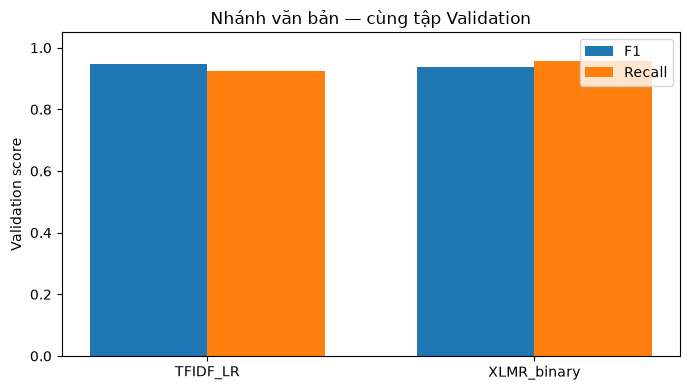

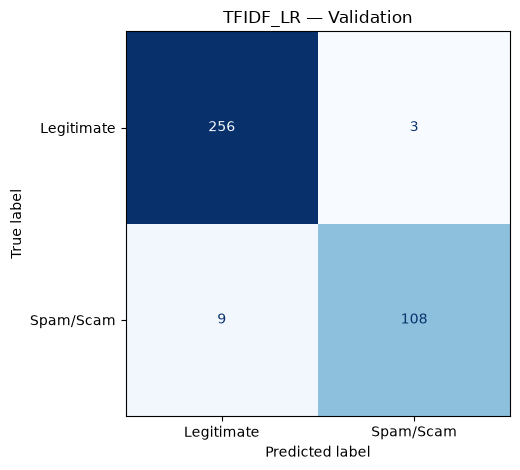

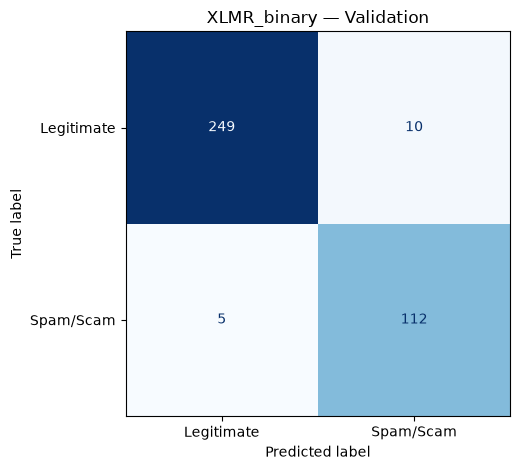

In [9]:
fig,ax=plt.subplots(figsize=(7,4))
xx=np.arange(len(val_table))
ax.bar(xx-0.18,val_table['f1'].values,width=0.36,label='F1')
ax.bar(xx+0.18,val_table['recall'].values,width=0.36,label='Recall')
ax.set_xticks(xx,val_table['model'].tolist())
ax.set_ylim(0,1.05);ax.set_ylabel('Validation score')
ax.set_title('Nhánh văn bản — cùng tập Validation')
ax.legend();fig.tight_layout()
fig.savefig(OUT_REPORTS/'text_validation_chart.png',dpi=200)
plt.show()
for name,value in comparison.items():
    cm=np.asarray(value['validation']['confusion_matrix'])
    disp=ConfusionMatrixDisplay(cm,display_labels=['Legitimate','Spam/Scam'])
    disp.plot(values_format='d',cmap='Blues',colorbar=False)
    plt.title(name+' — Validation')
    plt.tight_layout();plt.savefig(OUT_REPORTS/f'{name}_validation_confusion.png',dpi=200)
    plt.show()

## 8. Khóa lựa chọn và lưu báo cáo Validation

Lưu các số đo và phiên bản thư viện. Những dữ liệu này không khẳng định mô hình đã tích hợp Web hay Fusion đã được kiểm chứng. Giai đoạn Test là bước riêng, **chỉ chạy khi model và threshold đã khóa**.

In [10]:
audit={
  'task':'binary_source_sms_Legitimate_vs_SpamScam',
  'label_mapping':LABEL_MAP,
  'not_three_class_phishing_classifier':True,
  'seed':SEED,
  'n_splits':{s:int(df.split.eq(s).sum()) for s in ['train','validation','test']},
  'no_cross_split_group_overlap':True,
  'selected_on':'validation_only',
  'selected_text_model':SELECTED_TEXT_MODEL,
  'selected_threshold':SELECTED_THRESHOLD,
  'validation_metrics':comparison,
  'test_evaluated':False,
  'baseline_artifact':str(OUT_MODELS/'tfidf_lr_candidate.joblib'),
  'xlmr_checkpoint':str(OUT_MODELS/'xlmr_binary') if 'XLMR_binary' in comparison else None,
  'versions':{'python':platform.python_version(),'scikit_learn':sklearn.__version__,
     'torch': (torch.__version__ if 'torch' in globals() else None),
     'transformers': (transformers.__version__ if 'transformers' in globals() else None)},
  'risk_fusion_status':'not_evaluated_in_this_notebook',
}
(OUT_REPORTS/'text_validation_selection.json').write_text(json.dumps(audit,ensure_ascii=False,indent=2),encoding='utf-8')
print('Đã lưu:',OUT_REPORTS/'text_validation_selection.json')
print('Chỉ số đã có là Validation. Test chưa được dùng trong quy trình này.')

Đã lưu: C:\Users\ASUS\OneDrive - sad\Documents\Han\DATN\PhishGuardVN\PhishGuardVN_TD\reports\text_comparison\text_validation_selection.json
Chỉ số đã có là Validation. Test chưa được dùng trong quy trình này.


## 9. TEST ĐỘC LẬP — chỉ bật khi đã chốt mô hình trên Validation

**Chỉ thực hiện một lần cho bản đánh giá cuối:** sau khi các cell huấn luyện/Validation đã chạy xong, bỏ dấu `#` tại dòng `# RUN_FINAL_TEST = True` ở **cell Test bên dưới**, rồi **chỉ chạy cell Test**; không cần huấn luyện lại, không sửa mô hình/ngưỡng dựa trên kết quả Test. Bước này tính Test cho **cả hai mô hình đã huấn luyện** để minh bạch so sánh (nếu XLM-R đã chạy), nhưng quyết định chọn mô hình vẫn chỉ dựa trên Validation.

Nếu chỉ cần báo cáo chất lượng mô hình *được chọn* trên Test, dùng hàng tương ứng trong `text_test_comparison.csv`. Test không được dùng để chọn lại mô hình.

In [11]:
RUN_FINAL_TEST = True
if RUN_FINAL_TEST:
    test=df[df.split.eq('test')].copy()
    ytest=test.label.to_numpy()
    test_results={}
    base_p=baseline.predict_proba(test.input)[:,list(baseline.classes_).index(1)]
    test_results['TFIDF_LR']=score_binary(ytest,base_p,comparison['TFIDF_LR']['validation']['threshold'])
    if 'XLMR_binary' in comparison:
        test_ds=SmsDataset(test,tokenizer,MAX_LENGTH)
        test_logits=trainer.predict(test_ds).predictions
        if isinstance(test_logits,tuple):test_logits=test_logits[0]
        test_prob=torch.softmax(torch.as_tensor(test_logits),dim=-1).cpu().numpy()[:,1]
        test_results['XLMR_binary']=score_binary(ytest,test_prob,comparison['XLMR_binary']['validation']['threshold'])
    test_table=pd.DataFrame([{'model':name,**m} for name,m in test_results.items()])
    display(test_table.drop(columns='confusion_matrix'))
    test_table.to_csv(OUT_REPORTS/'text_test_comparison.csv',index=False,encoding='utf-8-sig')
    audit['test_evaluated']=True
    audit['test_metrics']=test_results
    audit['test_used_for_fit_or_tuning']=False
    (OUT_REPORTS/'text_final_results.json').write_text(json.dumps(audit,ensure_ascii=False,indent=2),encoding='utf-8')
    print('TEST hoàn tất. KHÔNG thay đổi mô hình/ngưỡng bằng kết quả Test.')
else:
    print('Đã bỏ qua Test: RUN_FINAL_TEST=False. Không có kết quả Test mới.')

c:\Users\ASUS\OneDrive - sad\Documents\Han\DATN\PhishGuardVN\.venv312\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


,model,precision,recall,f1,fpr,pr_auc,brier,threshold,n
0,TFIDF_LR,0.895238,0.94,0.917073,0.045082,0.969713,0.047774,0.52,344
1,XLMR_binary,0.941176,0.96,0.950495,0.024590,0.981365,0.027992,0.32,344


TEST hoàn tất. KHÔNG thay đổi mô hình/ngưỡng bằng kết quả Test.


## 10. Kết luận và hướng tích hợp Web / Risk Fusion

1. **Nếu XLM-R chưa chạy:** Chỉ có baseline TF-IDF + LR; không được báo cáo có điểm XLM-R.
2. **Nếu XLM-R đã chạy:** Dựa vào `reports/text_comparison/text_validation_comparison.csv` để chọn; sau đó dùng `text_test_comparison.csv` để báo cáo Test.
3. **Không thay thế tự động** `models/text_model.joblib` hoặc sửa `phishguard/engine.py`. Việc triển khai XLM-R lên API cần bước tích hợp và kiểm thử riêng.
4. Điểm phân loại văn bản ở đây là xác suất **Spam/Scam theo nhãn nguồn**, **không phải** xác suất phishing ba lớp. Bất kỳ bảng kết quả **Text+URL** nào cũng cần dữ liệu nhãn cặp thực được xác minh; Fusion hiện có là *proxy-only*.
5. Đưa bảng số liệu Validation/Test, confusion matrix, cấu hình và giới hạn vào Chương 3. Các số liệu chưa có phải để trống, không đoán.

**Các tệp xuất:** `models/text_comparison/tfidf_lr_candidate.joblib`; nếu XLM-R chạy sẽ có `models/text_comparison/xlmr_binary/`; các bảng, ảnh, JSON nằm trong `reports/text_comparison/`.